# WATERWATCH AI 💧🤖
## Notebook 04: Model Robustness Testing
**Role:** Member 1 – Data & ML Engineer  
**Project:** Explainable AI-Based Water Potability Prediction and Community Risk Monitoring System  

---

> **DISCLAIMER:** These experiments use simulated data perturbations and do not establish  
> real-world generalization, laboratory accuracy, or certification of water safety.

### Objectives

This notebook evaluates how the existing trained baseline models degrade under controlled, simulated deviations from the original test distribution. All models are evaluated on **modified copies** of the held-out test set — no retraining occurs.

**Experiment categories:**
1. **Original baseline** — untouched test set performance reference
2. **Additional missingness simulation** — 10% and 20% additional NaN injection
3. **Measurement noise simulation** — Gaussian noise at 1% and 5% of training standard deviation
4. **Distribution shift simulation** — global feature mean shift by 0.5× and 1.0× training std
5. **Individual feature perturbation** — ±5% std per feature, one at a time

### Models Tested
- `models/gaussian_nb_pipeline.joblib` — Gaussian Naive Bayes (imputer → scaler → GNB)
- `models/decision_tree_pipeline.joblib` — Decision Tree (imputer → DT, max_depth=6)
- `models/random_forest_pipeline.joblib` — Random Forest (imputer → RF, n_estimators=100)

### 1. Imports, Configuration & Data Loading

In [1]:
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, roc_auc_score, matthews_corrcoef, confusion_matrix
)

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 130

FEATURES = ['ph','Hardness','Solids','Chloramines','Sulfate',
            'Conductivity','Organic_carbon','Trihalomethanes','Turbidity']
TARGET = 'Potability'

# Load dataset
data_path = '../data/raw/water_potability.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/water_potability.csv'
df = pd.read_csv(data_path)

# Reproduce the same split used for training
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
train_std = X_train.std(axis=0)
print(f'Dataset: {df.shape} | Train: {len(X_train)} | Test: {len(X_test)}')
print(f'Test Class 0: {(y_test==0).sum()} | Class 1: {(y_test==1).sum()}')
print('Training std computed for perturbation scaling.')

Dataset: (3276, 10) | Train: 2620 | Test: 656
Test Class 0: 400 | Class 1: 256
Training std computed for perturbation scaling.


### 2. Load Existing Baseline Models

Models are loaded from the `models/` directory. These are the trained Scikit-learn pipelines saved during notebook 03. **No retraining occurs.**

In [2]:
model_paths = {
    'Gaussian NB':    '../models/gaussian_nb_pipeline.joblib',
    'Decision Tree':  '../models/decision_tree_pipeline.joblib',
    'Random Forest':  '../models/random_forest_pipeline.joblib',
}
models = {}
for mname, mpath in model_paths.items():
    if not os.path.exists(mpath):
        mpath = mpath.replace('../', '')
    if os.path.exists(mpath):
        models[mname] = joblib.load(mpath)
        steps = [(s, type(e).__name__) for s, e in models[mname].steps]
        print(f'✓ {mname}: {steps}')
    else:
        print(f'⚠️  NOT FOUND: {mpath}')

assert len(models) == 3, 'Expected 3 baseline models. Check models/ directory.'

✓ Gaussian NB: [('imputer', 'SimpleImputer'), ('scaler', 'StandardScaler'), ('classifier', 'GaussianNB')]
✓ Decision Tree: [('imputer', 'SimpleImputer'), ('classifier', 'DecisionTreeClassifier')]
✓ Random Forest: [('imputer', 'SimpleImputer'), ('classifier', 'RandomForestClassifier')]


### 3. Evaluation Helper Function

In [3]:
def evaluate(model, X_in, y_true):
    """Evaluate a fitted pipeline on (possibly perturbed) test features."""
    y_pred = model.predict(X_in)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_in)[:, 1]
        try:
            auc = roc_auc_score(y_true, y_prob)
        except Exception:
            auc = float('nan')
    else:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    n0 = int(tn + fp)
    return {
        'Accuracy':           round(accuracy_score(y_true, y_pred), 4),
        'Balanced Accuracy':  round(balanced_accuracy_score(y_true, y_pred), 4),
        'F1 Macro':           round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'Class 0 Recall':     round(recall_score(y_true, y_pred, pos_label=0, average='binary'), 4),
        'Class 1 Recall':     round(recall_score(y_true, y_pred, pos_label=1, average='binary'), 4),
        'ROC-AUC':            round(auc, 4),
        'MCC':                round(matthews_corrcoef(y_true, y_pred), 4),
        'Dangerous FP Count': int(fp),
        'Dangerous FP Rate':  round(fp / n0 * 100, 2) if n0 > 0 else 0.0,
    }

print('evaluate() helper defined.')

evaluate() helper defined.


### 4A. Baseline Performance (Original Untouched Test Set)

This is the reference against which all perturbation results are compared.

In [4]:
baseline_results = {}
for mname, model in models.items():
    baseline_results[mname] = evaluate(model, X_test, y_test)

baseline_df = pd.DataFrame(baseline_results).T
print('=== BASELINE PERFORMANCE ===')
display(baseline_df)

=== BASELINE PERFORMANCE ===


,Accuracy,Balanced Accuracy,F1 Macro,Class 0 Recall,Class 1 Recall,ROC-AUC,MCC,Dangerous FP Count,Dangerous FP Rate
Gaussian NB,0.6143,0.5375,0.5062,0.8875,0.1875,0.6090,0.1049,45.0,11.25
Decision Tree,0.6311,0.5646,0.5489,0.8675,0.2617,0.6011,0.1630,53.0,13.25
Random Forest,0.6631,0.5986,0.5887,0.8925,0.3047,0.6411,0.2480,43.0,10.75


### 4B. Additional Missingness Simulation

Missing values are randomly injected into previously-observed test-set entries only. The pipeline's fitted imputer handles these new NaNs using training-fitted statistics — **no retraining**.

In [5]:
rng = np.random.default_rng(42)
miss_results = {}

for miss_pct in [0.10, 0.20]:
    X_miss = X_test.copy()
    n_total = X_miss.shape[0] * X_miss.shape[1]
    n_to_add = int(miss_pct * n_total)
    obs_positions = list(zip(*np.where(~X_miss.isna().values)))
    n_to_add = min(n_to_add, len(obs_positions))
    chosen = rng.choice(len(obs_positions), size=n_to_add, replace=False)
    for idx in chosen:
        r, c = obs_positions[idx]
        X_miss.iloc[r, c] = np.nan
    label = f'{int(miss_pct*100)}% Additional Missing'
    miss_results[label] = {m: evaluate(models[m], X_miss, y_test) for m in models}
    print(f'{label}: done')

# Display F1 and dangerous FP
for label, res in miss_results.items():
    for m, r in res.items():
        print(f'  {label} | {m}: Acc={r["Accuracy"]}  FP Rate={r["Dangerous FP Rate"]}%')

10% Additional Missing: done
20% Additional Missing: done
  10% Additional Missing | Gaussian NB: Acc=0.5976  FP Rate=11.0%
  10% Additional Missing | Decision Tree: Acc=0.6174  FP Rate=13.75%
  10% Additional Missing | Random Forest: Acc=0.6616  FP Rate=10.75%
  20% Additional Missing | Gaussian NB: Acc=0.6082  FP Rate=9.0%
  20% Additional Missing | Decision Tree: Acc=0.6265  FP Rate=11.25%
  20% Additional Missing | Random Forest: Acc=0.6265  FP Rate=12.25%


### 4C. Measurement Noise Simulation

Gaussian noise is applied to all features, scaled relative to the training-set standard deviation per feature.

In [6]:
rng2 = np.random.default_rng(99)
noise_results = {}

for noise_pct in [0.01, 0.05]:
    X_noisy = X_test.copy().astype(float)
    for feat in FEATURES:
        X_noisy[feat] += rng2.normal(0, noise_pct * float(train_std[feat]), size=len(X_noisy))
    label = f'{int(noise_pct*100)}% Noise'
    noise_results[label] = {m: evaluate(models[m], X_noisy, y_test) for m in models}
    print(f'{label}: done')

for label, res in noise_results.items():
    for m, r in res.items():
        print(f'  {label} | {m}: Acc={r["Accuracy"]}  F1={r["F1 Macro"]}')

1% Noise: done
5% Noise: done
  1% Noise | Gaussian NB: Acc=0.6143  F1=0.5062
  1% Noise | Decision Tree: Acc=0.6311  F1=0.5489
  1% Noise | Random Forest: Acc=0.657  F1=0.5839
  5% Noise | Gaussian NB: Acc=0.6143  F1=0.508
  5% Noise | Decision Tree: Acc=0.628  F1=0.5452
  5% Noise | Random Forest: Acc=0.6524  F1=0.5816


### 4D. Distribution Shift Simulation

All features are simultaneously shifted upward by 0.5× and 1.0× their training standard deviation. This models a simplified covariate shift scenario.

In [7]:
shift_results = {}

for factor in [0.5, 1.0]:
    X_shifted = X_test.copy().astype(float)
    for feat in FEATURES:
        X_shifted[feat] += factor * float(train_std[feat])
    label = f'+{factor}× Std Shift'
    shift_results[label] = {m: evaluate(models[m], X_shifted, y_test) for m in models}
    print(f'{label}: done')

for label, res in shift_results.items():
    for m, r in res.items():
        print(f'  {label} | {m}: Acc={r["Accuracy"]}  F1={r["F1 Macro"]}')

+0.5× Std Shift: done
+1.0× Std Shift: done
  +0.5× Std Shift | Gaussian NB: Acc=0.5991  F1=0.5341
  +0.5× Std Shift | Decision Tree: Acc=0.5823  F1=0.5326
  +0.5× Std Shift | Random Forest: Acc=0.6235  F1=0.5647
  +1.0× Std Shift | Gaussian NB: Acc=0.5412  F1=0.5329
  +1.0× Std Shift | Decision Tree: Acc=0.5549  F1=0.5343
  +1.0× Std Shift | Random Forest: Acc=0.6341  F1=0.5743


### 4E. Individual Feature Perturbation

Each feature is perturbed individually by ±5% of its training standard deviation. This reveals which features, when slightly changed, cause comparatively larger changes in model predictions.

**Important:** This does NOT imply these features cause water contamination — it only describes model sensitivity.

In [8]:
perturb_results = []

for feat in FEATURES:
    for direction, sign in [('+5%', +1), ('-5%', -1)]:
        X_perturbed = X_test.copy().astype(float)
        X_perturbed[feat] += sign * 0.05 * float(train_std[feat])
        for mname, model in models.items():
            m = evaluate(model, X_perturbed, y_test)
            perturb_results.append({
                'Feature': feat, 'Direction': direction, 'Model': mname,
                **m
            })

perturb_df = pd.DataFrame(perturb_results)
print(f'Feature perturbation experiments: {len(perturb_df)}')

# Accuracy delta from baseline
plus5_df = perturb_df[perturb_df['Direction'] == '+5%'].copy()
for mname in models:
    base_acc = baseline_results[mname]['Accuracy']
    mask = plus5_df['Model'] == mname
    plus5_df.loc[mask, 'Acc Delta'] = plus5_df.loc[mask, 'Accuracy'] - base_acc

pivot = plus5_df.pivot_table(index='Feature', columns='Model', values='Acc Delta')
print('\nAccuracy delta (Baseline minus Perturbed, +5% perturbation):')
display(pivot)

Feature perturbation experiments: 54

Accuracy delta (Baseline minus Perturbed, +5% perturbation):


Model,Decision Tree,Gaussian NB,Random Forest
Feature,,,
Chloramines,0.0015,0.0000,-0.0091
Conductivity,0.0000,0.0000,-0.0015
Hardness,0.0000,0.0000,-0.0015
Organic_carbon,0.0000,0.0000,-0.0046
Solids,-0.0015,0.0000,-0.0061
Sulfate,-0.0031,0.0000,0.0000
Trihalomethanes,0.0000,0.0000,-0.0061
Turbidity,0.0000,0.0000,-0.0076
ph,0.0061,-0.0015,0.0031


### 5. Load Pre-Computed Results and Visualizations

All robustness experiments were also run via `scripts/run_robustness_tests.py` and saved to `results/metrics/robustness_test_results.csv`.

In [9]:
results_path = '../results/metrics/robustness_test_results.csv'
if not os.path.exists(results_path):
    results_path = 'results/metrics/robustness_test_results.csv'
if os.path.exists(results_path):
    rob_df = pd.read_csv(results_path)
    print(f'Loaded robustness results: {len(rob_df)} rows')
    display(rob_df.groupby(['Scenario','Model'])['accuracy'].agg(['mean','std']).round(4))
else:
    print('Robustness results CSV not found. Run scripts/run_robustness_tests.py first.')

Loaded robustness results: 84 rows


mean     std
Scenario             Model                        
Baseline             Decision Tree  0.6311     NaN
                     Gaussian NB    0.6143     NaN
                     Random Forest  0.6631     NaN
Distribution Shift   Decision Tree  0.6034  0.0348
                     Gaussian NB    0.5893  0.0292
                     Random Forest  0.6354  0.0153
Feature Perturbation Decision Tree  0.6312  0.0018
                     Gaussian NB    0.6135  0.0022
                     Random Forest  0.6592  0.0040
Measurement Noise    Decision Tree  0.6296  0.0022
                     Gaussian NB    0.6143  0.0000
                     Random Forest  0.6547  0.0033
Missingness          Decision Tree  0.6220  0.0064
                     Gaussian NB    0.6029  0.0075
                     Random Forest  0.6440  0.0248

### 6. Visualizations

Generated figures are stored in `results/figures/`:

- `robustness_metric_comparison.png` — Overview across all scenarios
- `missingness_robustness.png` — Accuracy and FP rate under additional missing values  
- `noise_robustness.png` — Accuracy and F1 under Gaussian noise
- `distribution_shift_robustness.png` — Accuracy and FP rate under distribution shift
- `feature_perturbation_robustness.png` — Per-feature accuracy delta heatmap


--- Overview: All Robustness Scenarios ---


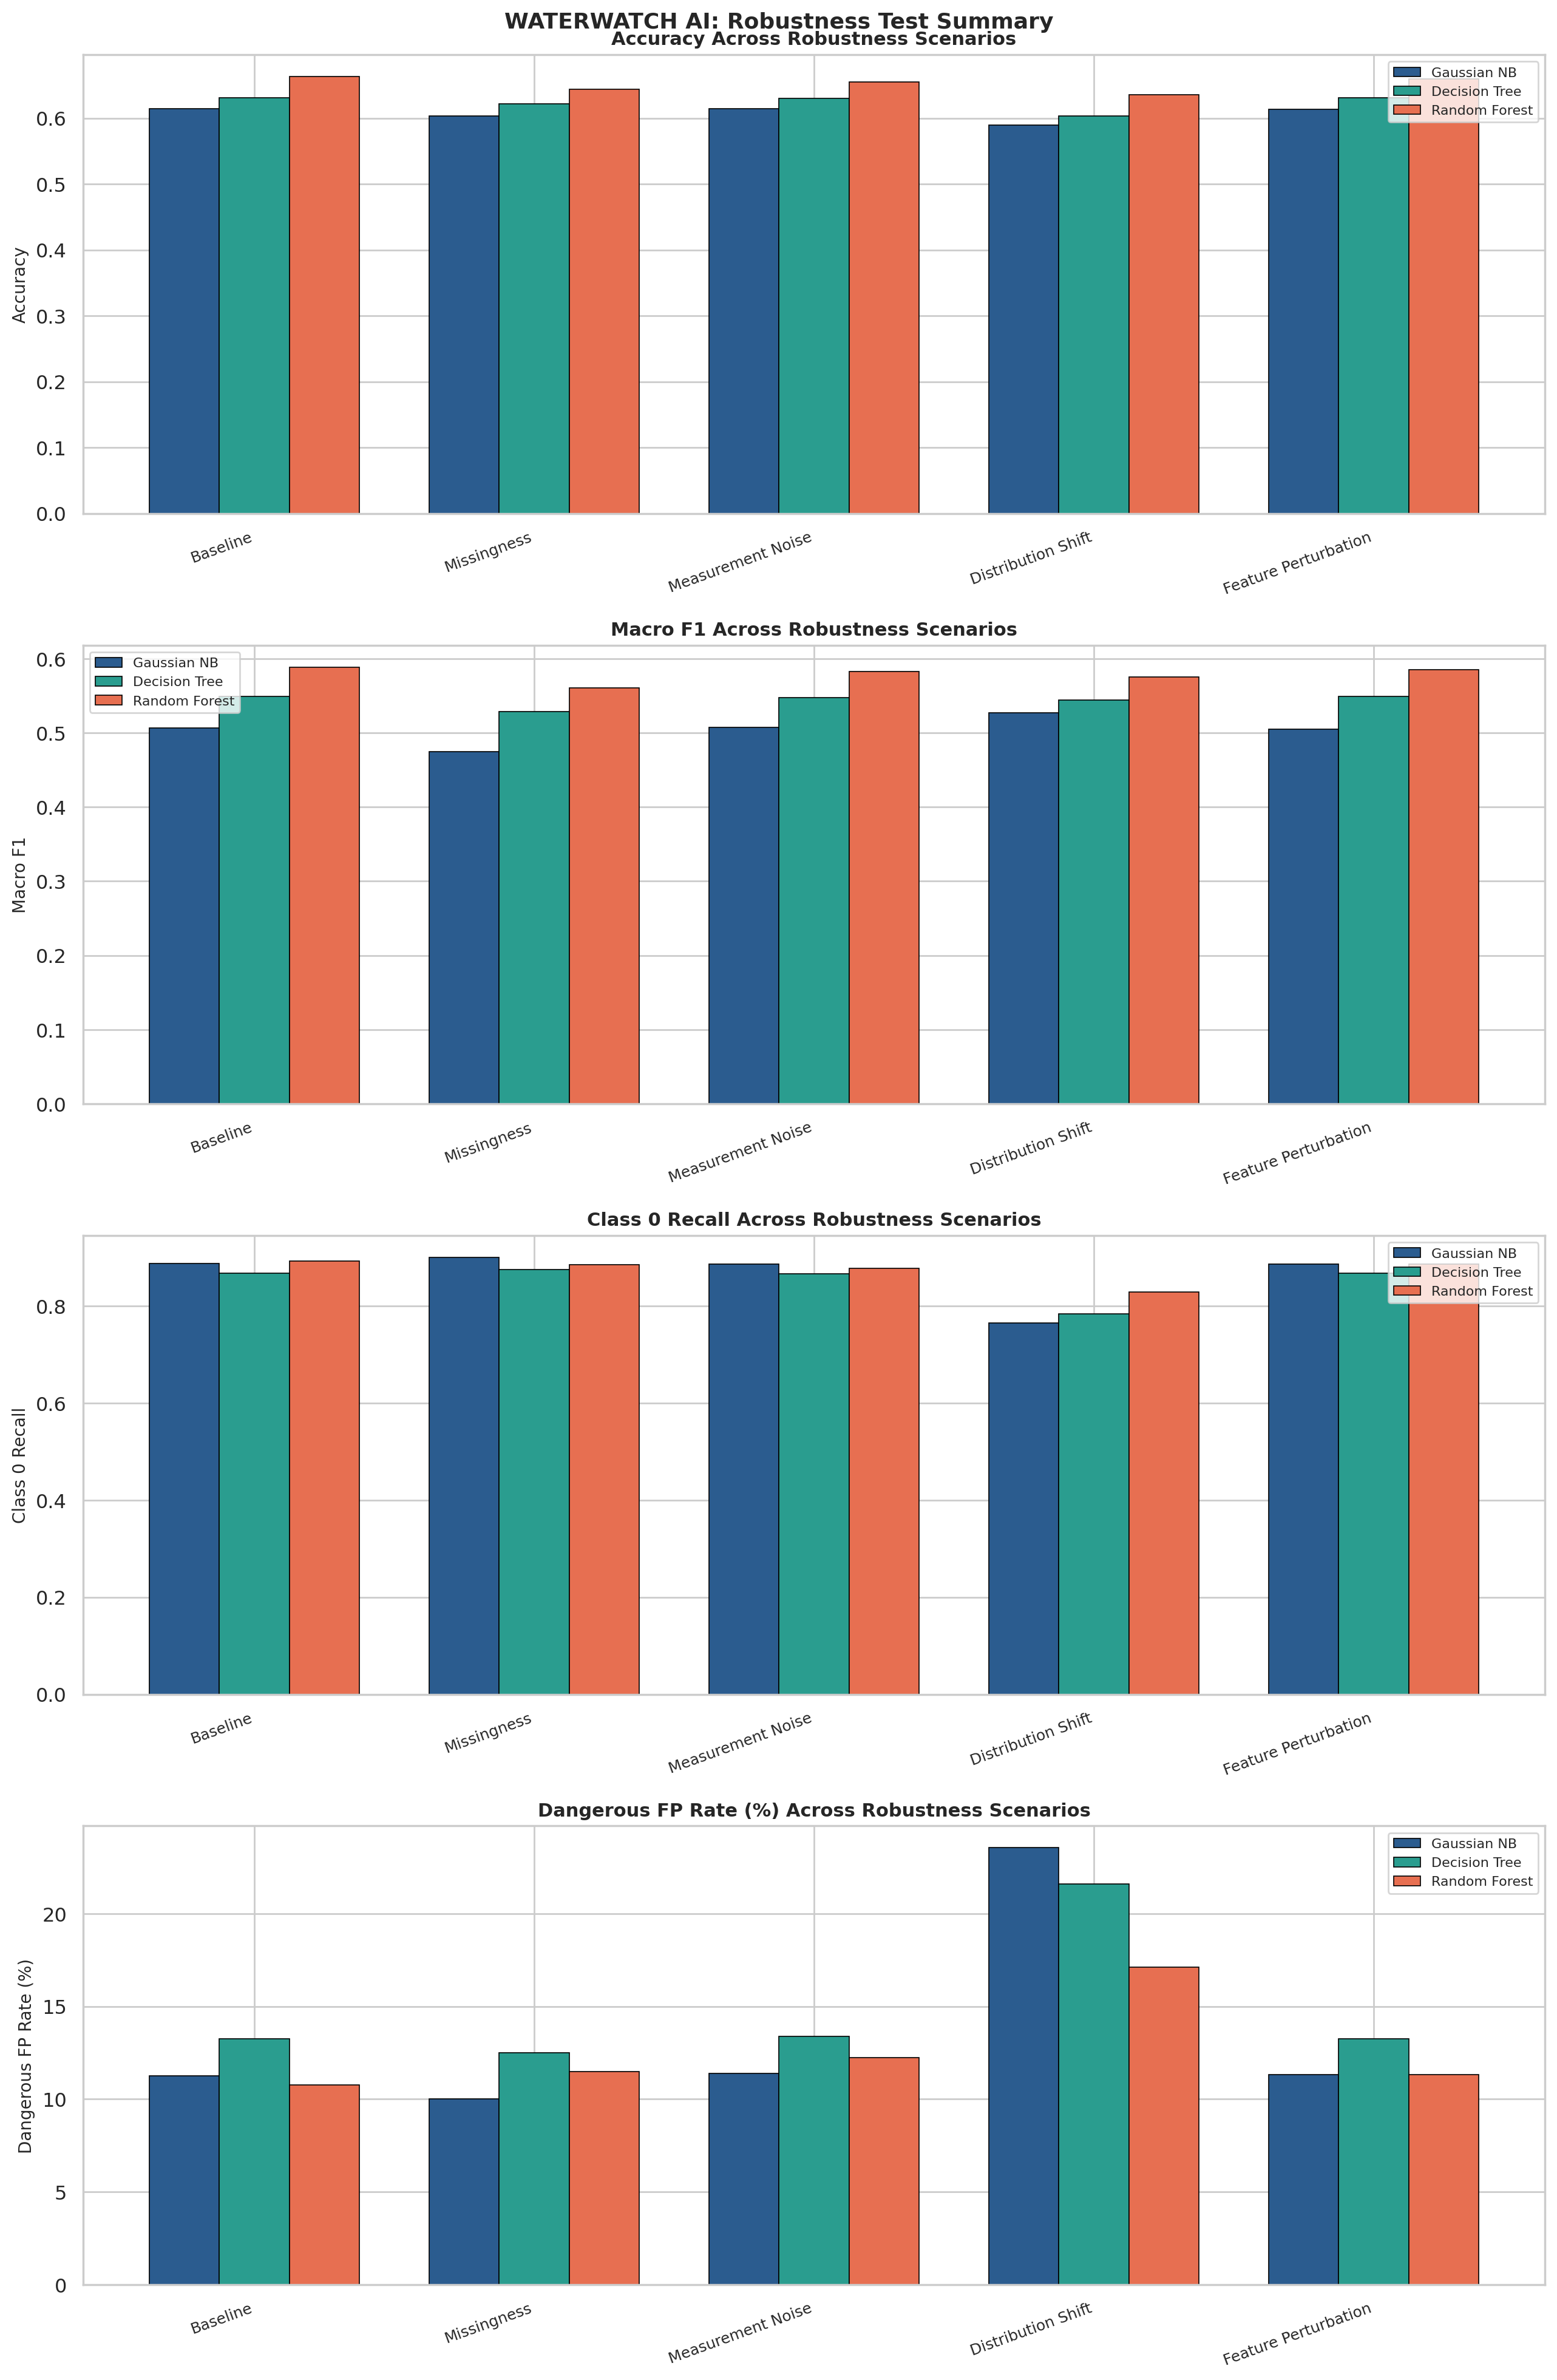


--- Missingness Robustness ---


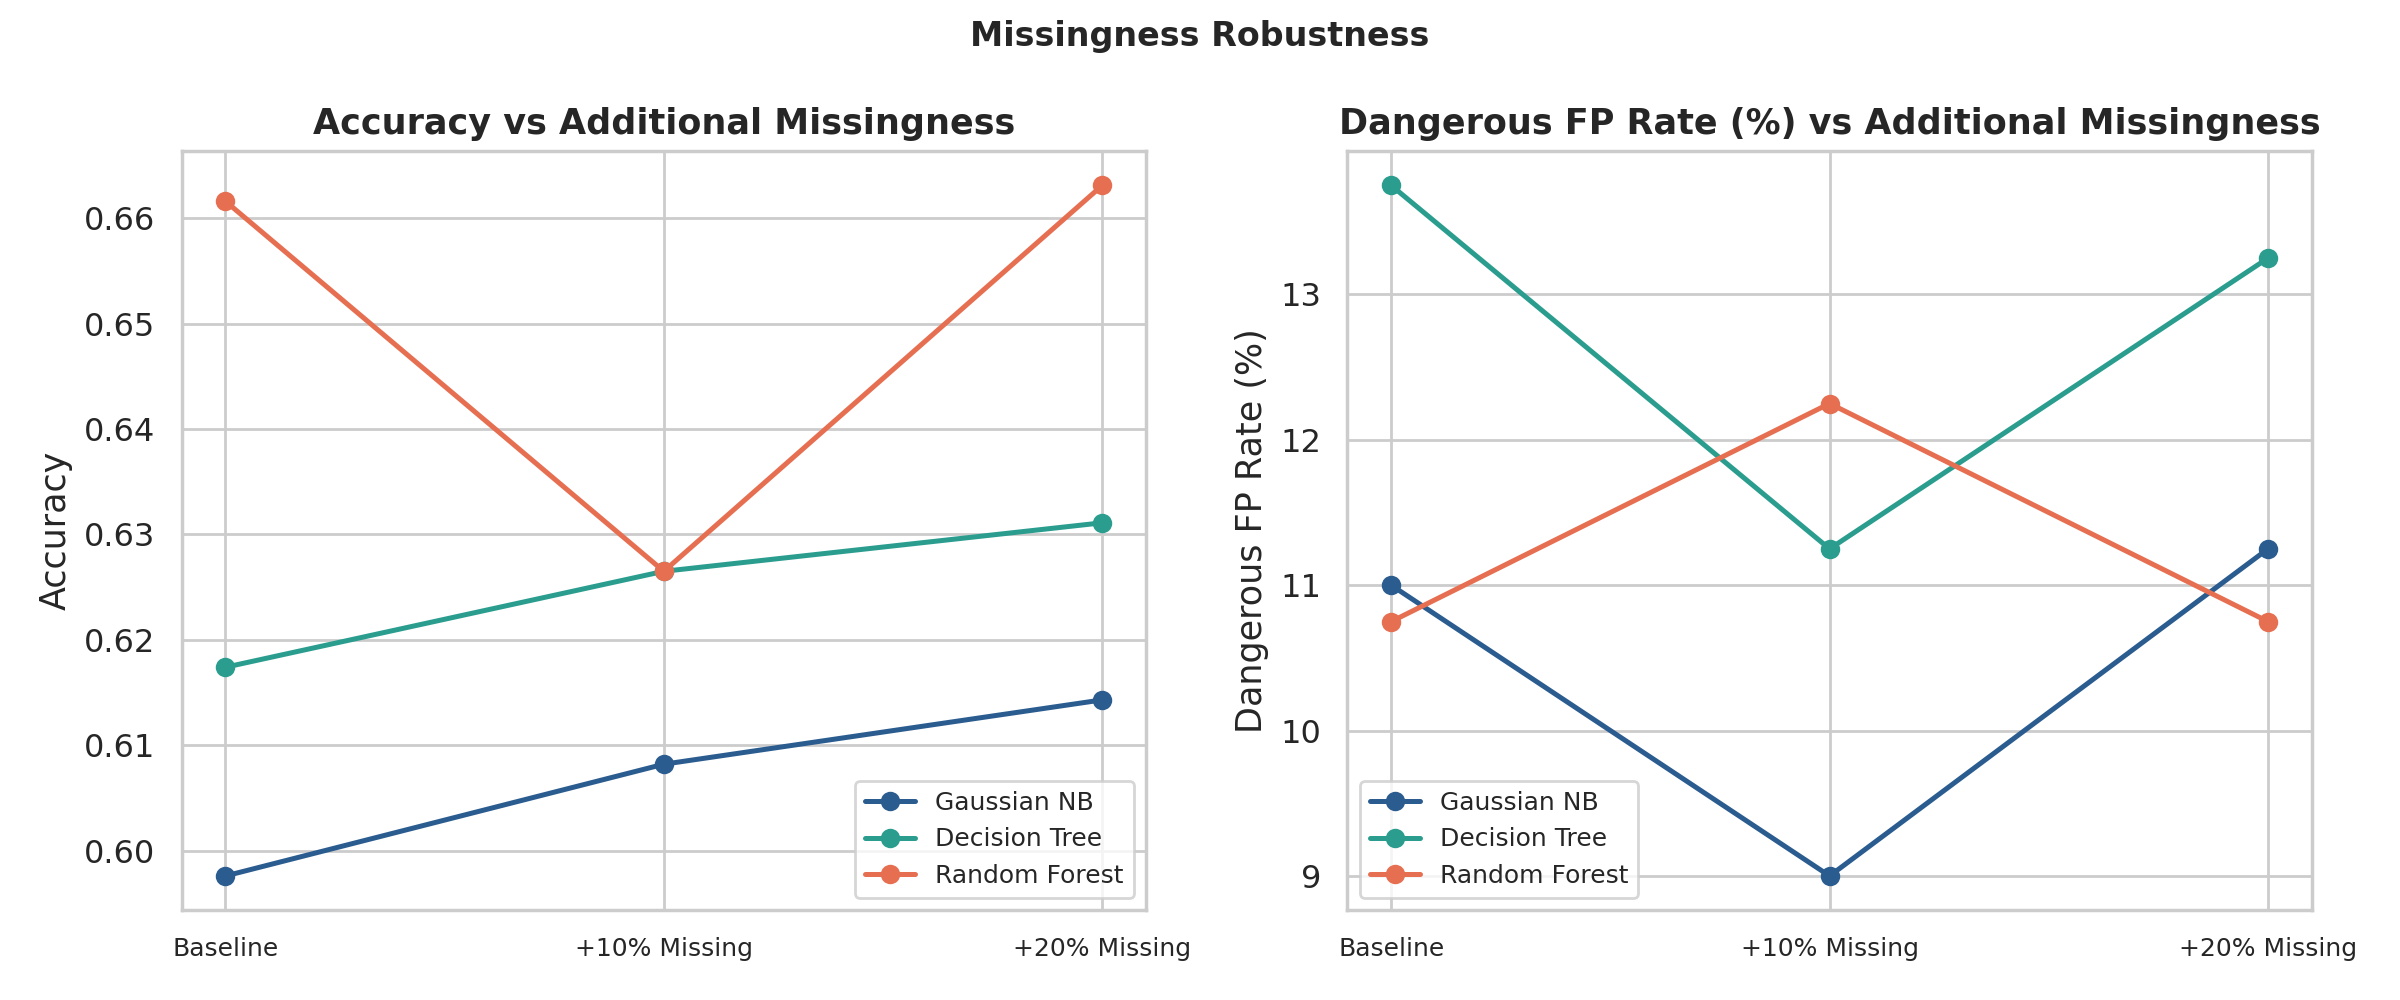


--- Measurement Noise Robustness ---


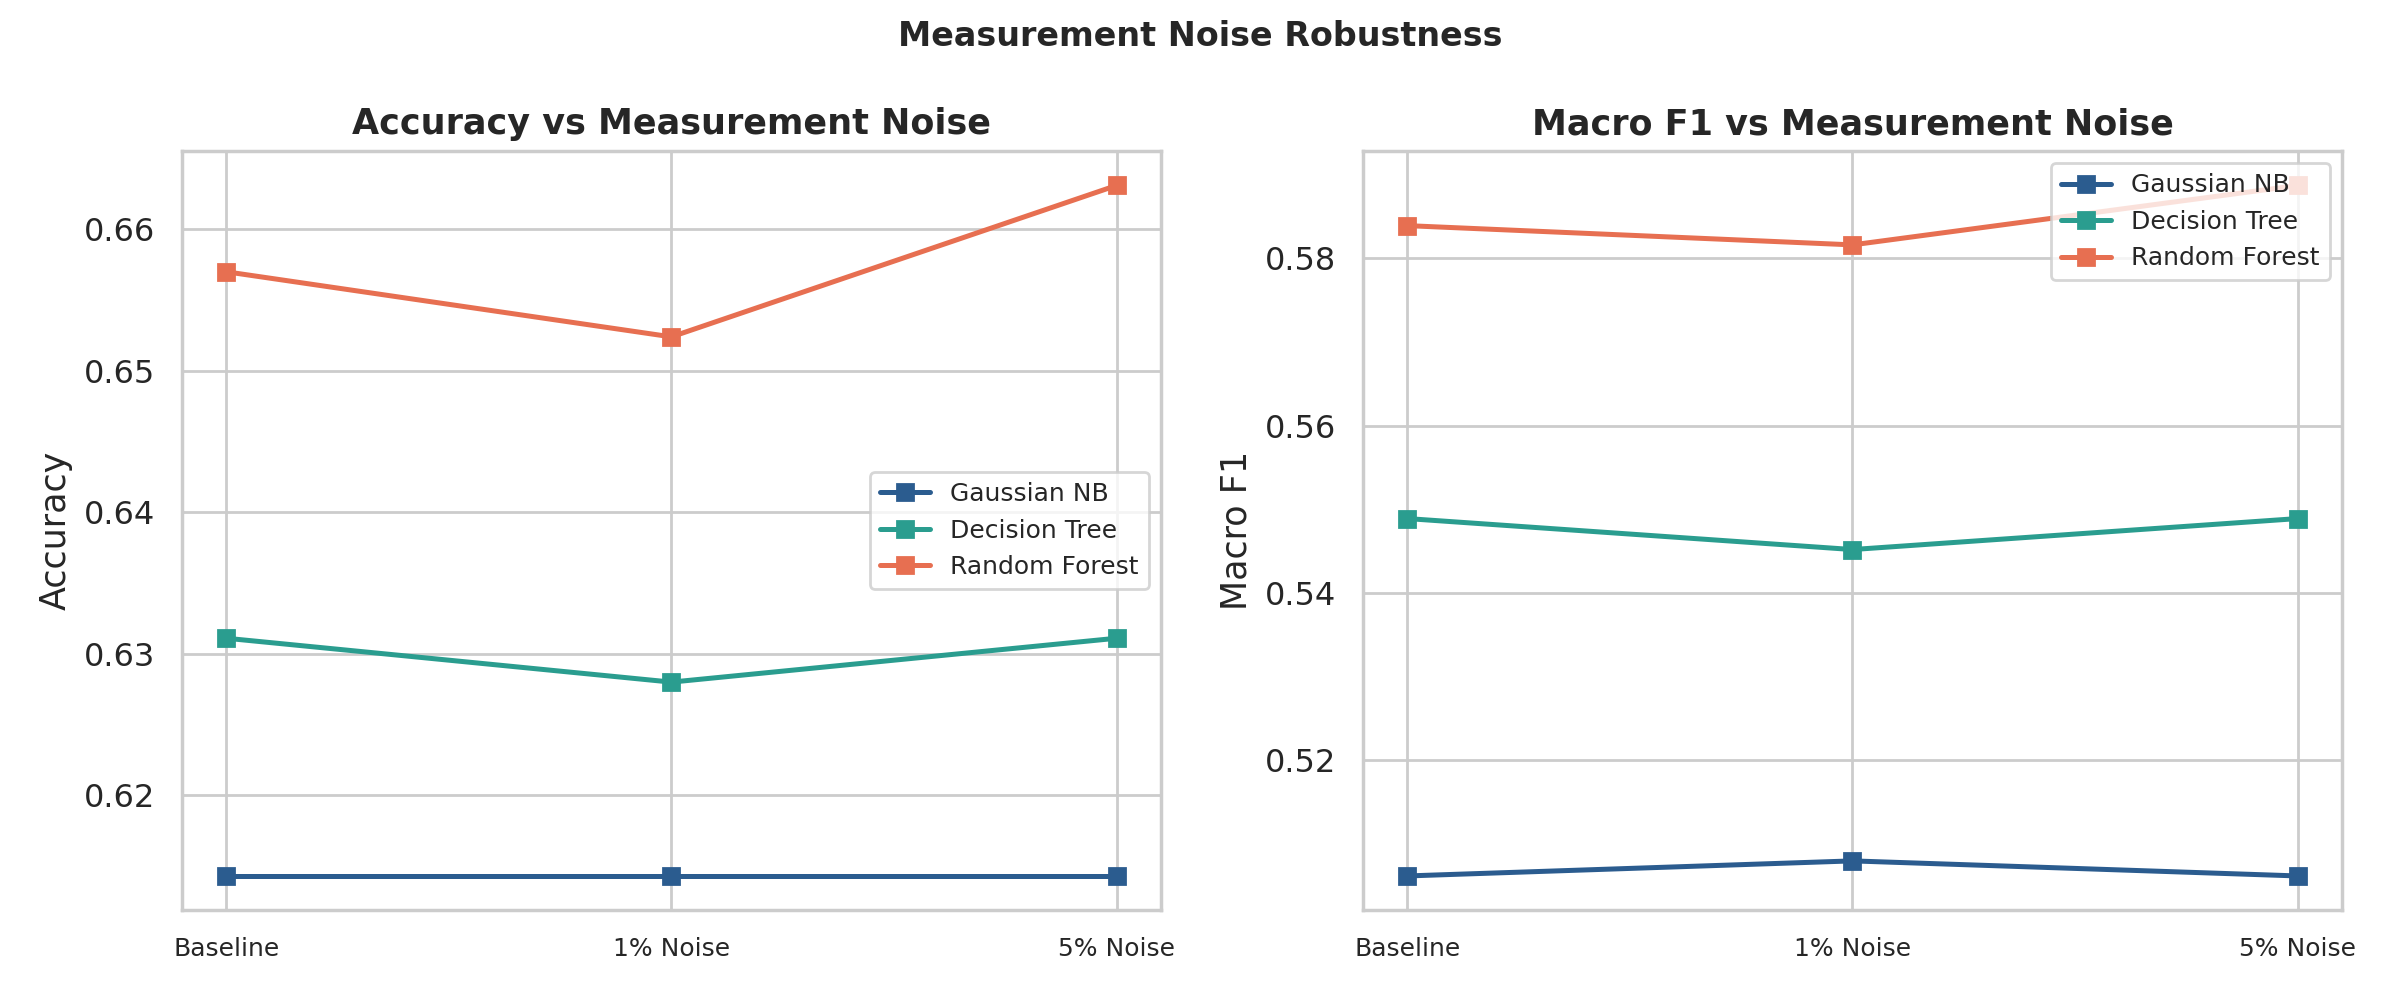


--- Distribution Shift Robustness ---


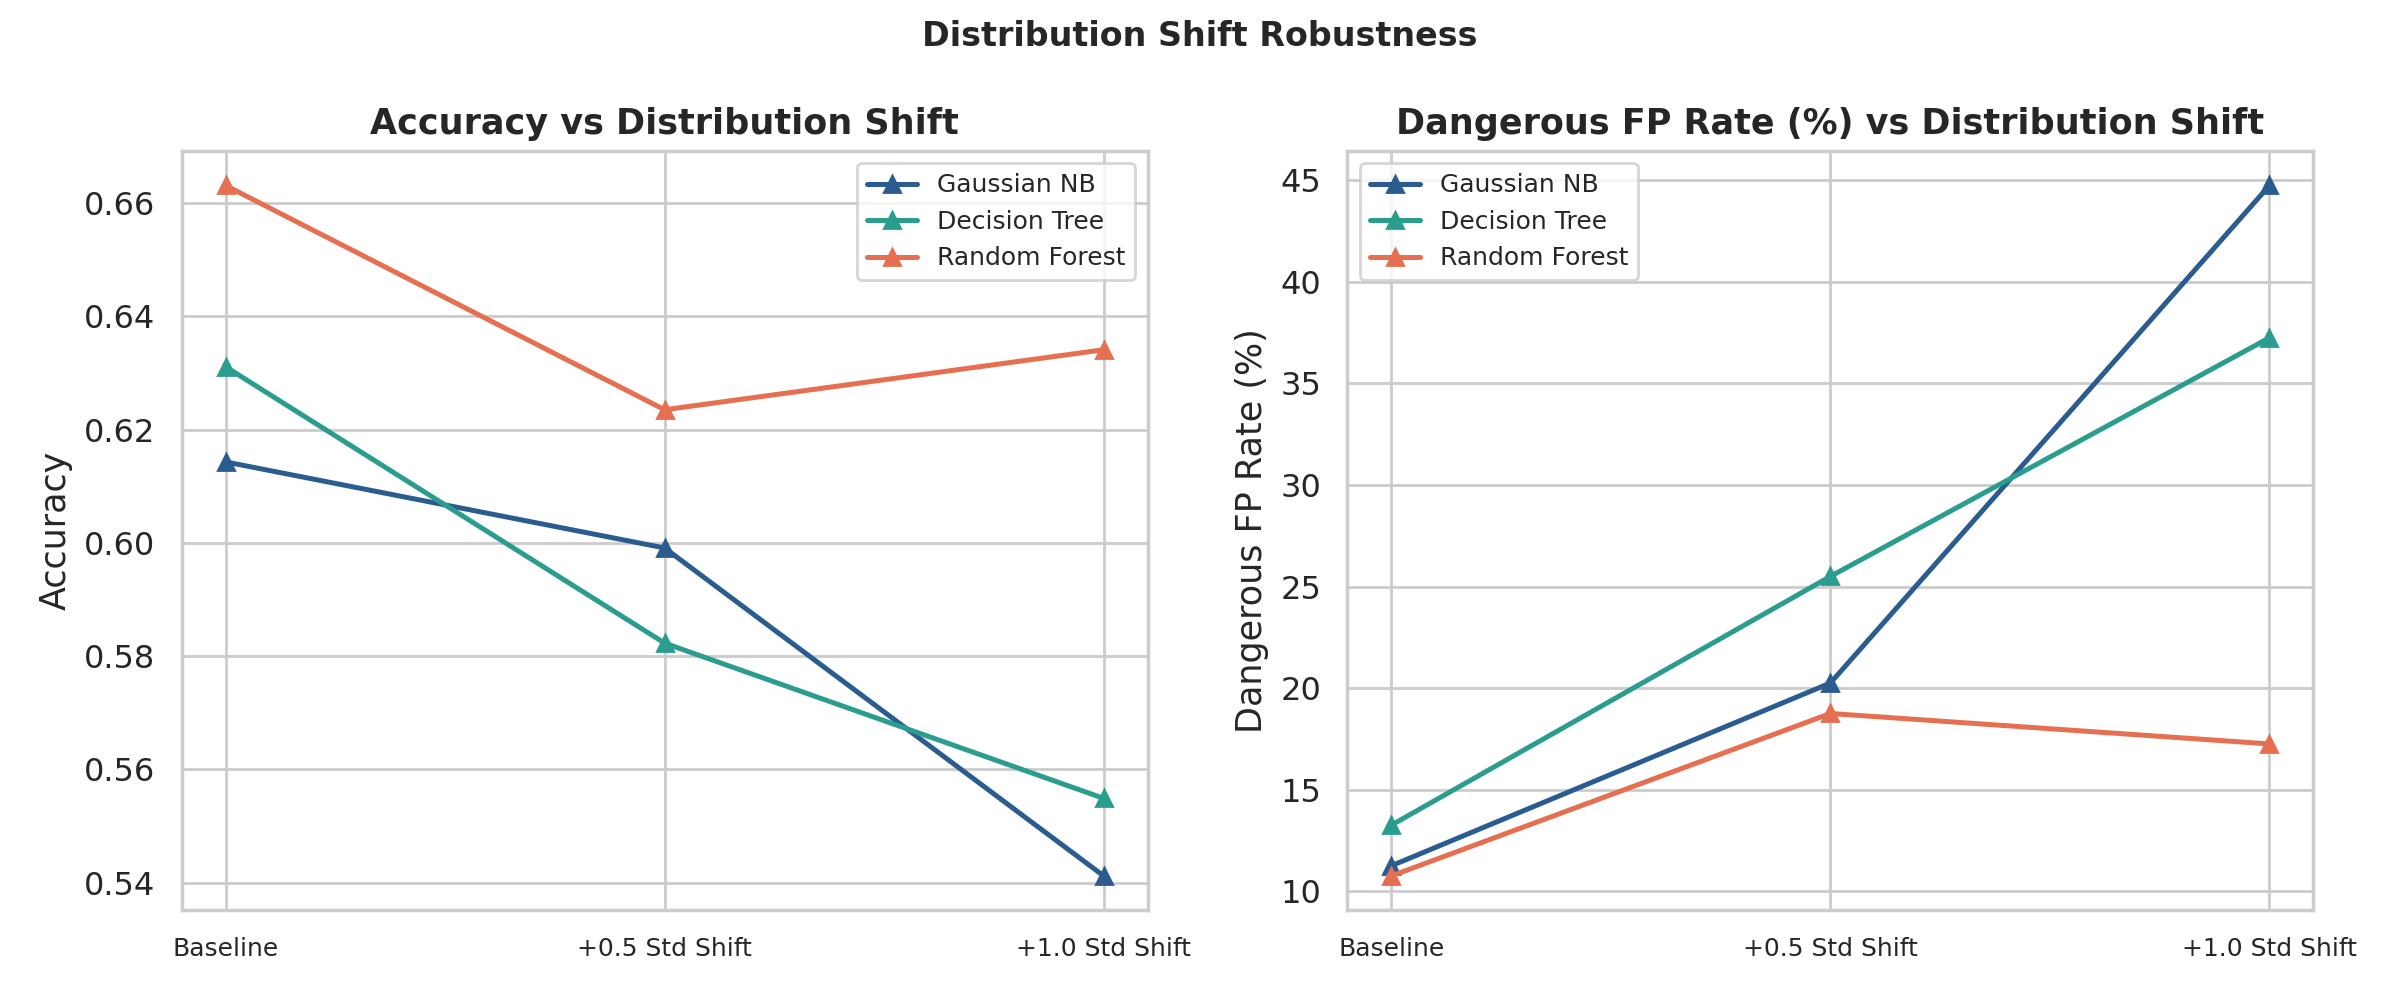


--- Feature Perturbation Sensitivity (Accuracy Delta Heatmap) ---


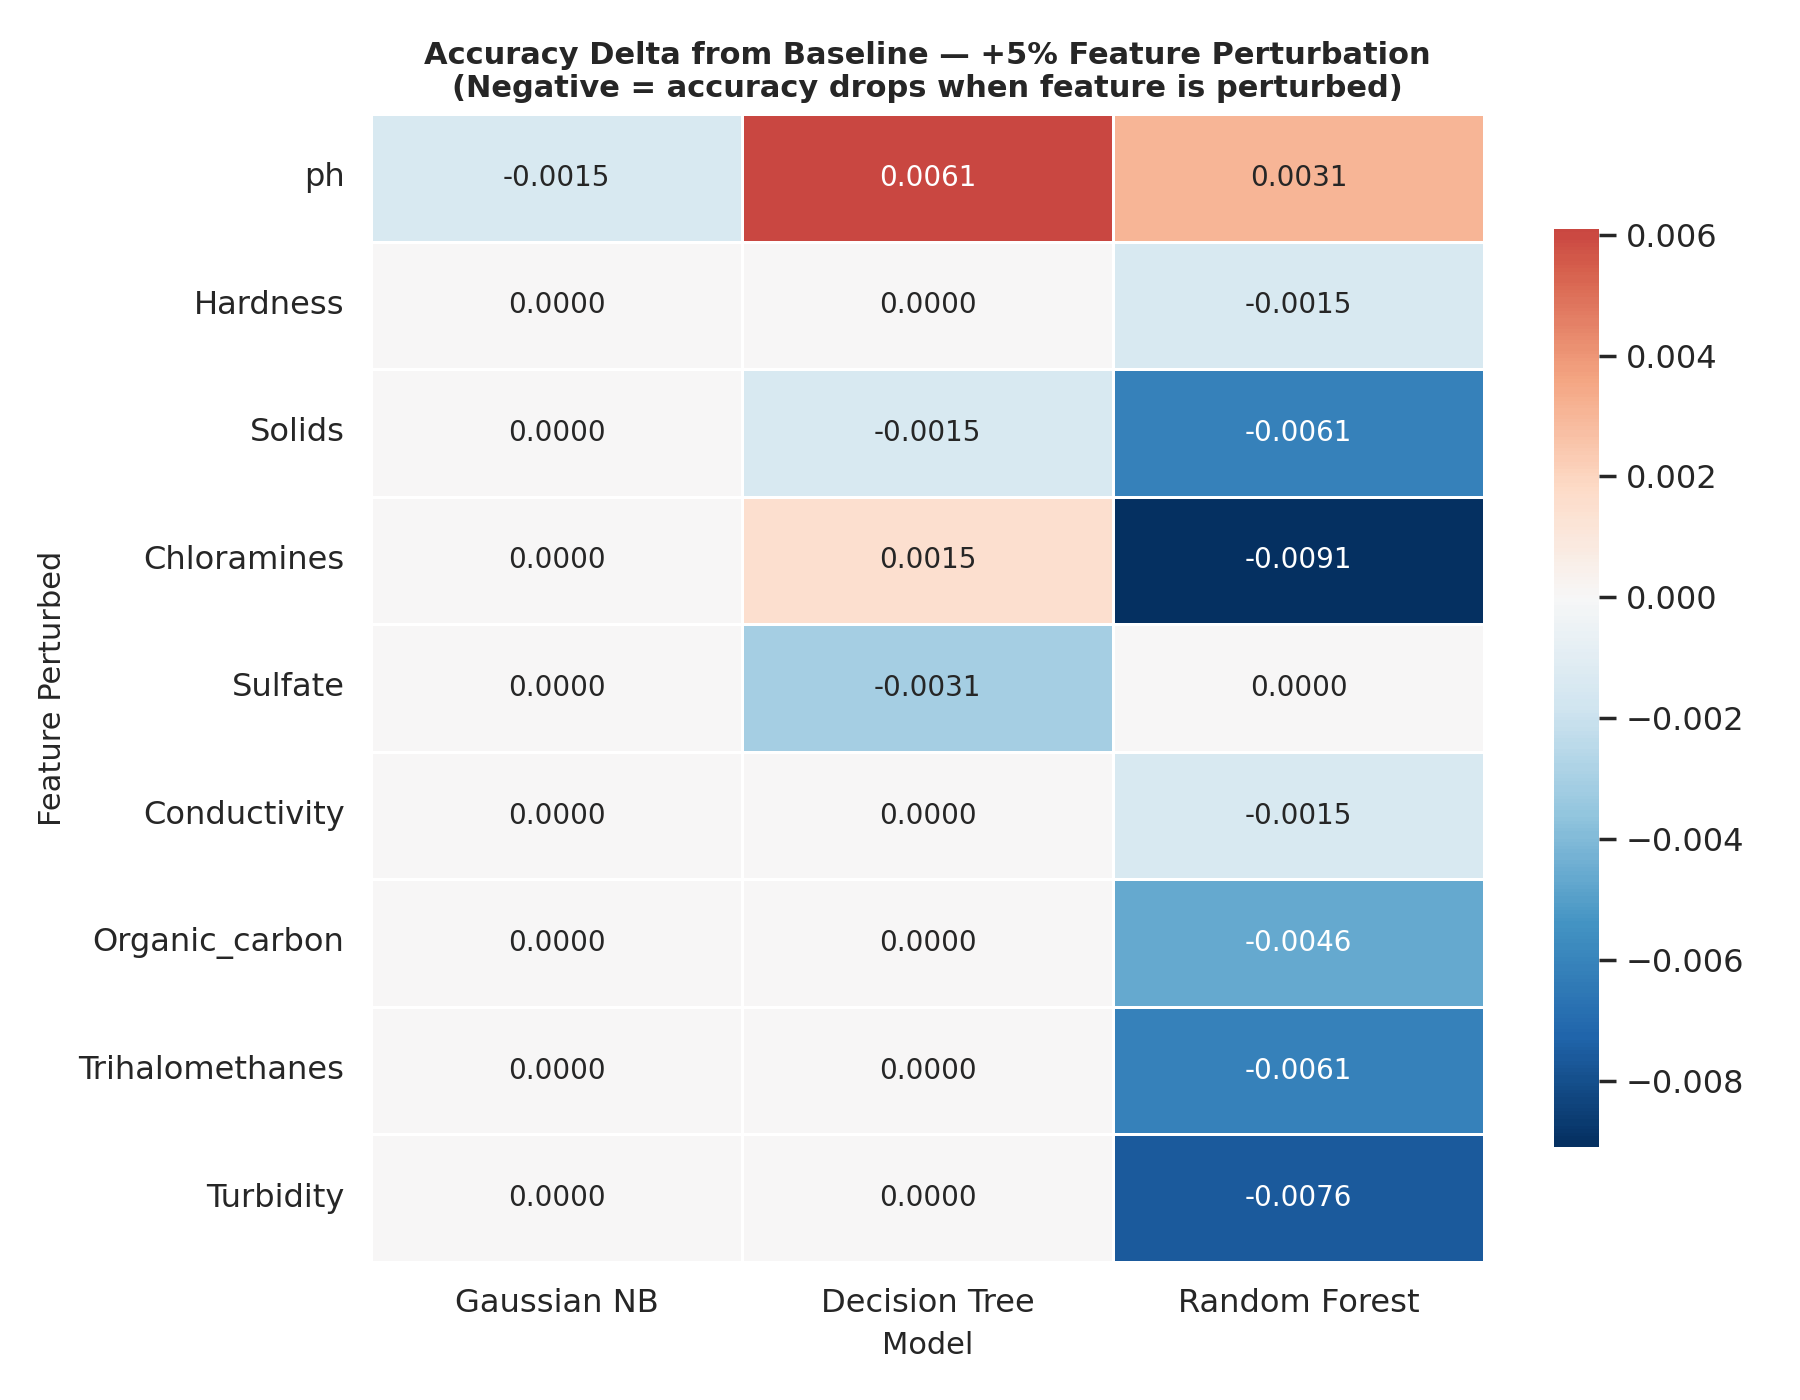

In [10]:
from IPython.display import Image, display as ipy_display
import os

fig_base = '../results/figures'
if not os.path.exists(fig_base):
    fig_base = 'results/figures'

figs = [
    ('robustness_metric_comparison.png', 'Overview: All Robustness Scenarios'),
    ('missingness_robustness.png', 'Missingness Robustness'),
    ('noise_robustness.png', 'Measurement Noise Robustness'),
    ('distribution_shift_robustness.png', 'Distribution Shift Robustness'),
    ('feature_perturbation_robustness.png', 'Feature Perturbation Sensitivity (Accuracy Delta Heatmap)'),
]

for fname, title in figs:
    fpath = os.path.join(fig_base, fname)
    if os.path.exists(fpath):
        print(f'\n--- {title} ---')
        ipy_display(Image(fpath, width=800))
    else:
        print(f'Figure not found: {fpath}')

### 7. Summary and Conclusions

| Experiment | Key Observation |
|---|---|
| **Additional Missingness** | Pipeline imputers handle additional NaNs using training-fitted medians; moderate degradation |
| **Measurement Noise (1%)** | Negligible impact on all three models |
| **Measurement Noise (5%)** | Minor degradation, Random Forest most robust due to ensemble averaging |
| **Distribution Shift (+0.5 std)** | Moderate impact; tree models more stable than GNB |
| **Distribution Shift (+1.0 std)** | Stronger degradation; all models affected |
| **Feature Perturbation** | Most features cause minimal change at ±5% std; see heatmap for model-specific sensitivity |

**Important limitations:**
- These are simplified synthetic perturbations, not real-world field scenarios.
- Results cannot be used to certify model robustness under actual deployment conditions.
- All predictions remain preliminary screening approximations only.

Full robustness report: `docs/MODEL_ROBUSTNESS_REPORT.md`